### Step 1: Setup and State Definition

#### 1a. Install and import

In [80]:
!pip install -U langgraph langchain-openai python-dotenv

In [81]:
import os
from typing import TypedDict, List, Literal
from dotenv import load_dotenv

from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

load_dotenv()

# Make sure OPENAI_API_KEY is set in your .env file
print("OpenAI API Key loaded:", "OPENAI_API_KEY" in os.environ)

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

OpenAI API Key loaded: True


#### 1b. Define the state

In [82]:
class  ComplaintState(TypedDict):
            complaint: str
            category: str
            workflow_path: List[str]
            status: str
            is_valid: bool
            validation_notes: str
            investigation: str
            evidence: List[str]
            resolution: str
            final_message: str



In [83]:
initial_state: ComplaintState = {
    "complaint": (
        "The Downside Up portal opens at different times each day. "
        "How do I predict when?"
    ),
    "category": "",
    "workflow_path": [],
    "status": "new",
    "is_valid": False,
}

print(initial_state)

{'complaint': 'The Downside Up portal opens at different times each day. How do I predict when?', 'category': '', 'workflow_path': [], 'status': 'new', 'is_valid': False}


### Step 2: Define Workflow Nodes

#### 2a. Lore

In [84]:
VALID_CATEGORIES = ["portal", "monster", "psychic", "environmental"]

LORE = {
    "portal": "Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.",
    "monster": "Demogorgons act alone when hunting, but follow a hive mind when a larger entity controls them.",
    "psychic": "Psychic power drains the user's energy. Bigger or heavier objects need more energy, and nosebleeds are a warning sign.",
    "environmental": "Creatures from the Downside Up disturb electricity: lights flicker and power lines react when they are near.",
}

#### 2b. Intake node

In [85]:
def intake_node(state: ComplaintState) -> ComplaintState:
    """Step 1: Intake - Parse and categorize the complaint"""
    print("\n[INTAKE] Processing complaint...")

    complaint = state["complaint"]

    # Categorize complaint using LLM
    categorization_prompt = f"""Categorize this Downside Up complaint into one of these categories:
- portal: Issues with portal timing, location, or behavior
- monster: Issues with creature behavior (demogorgons, etc.)
- psychic: Issues with psychic abilities or limitations
- environmental: Issues with electricity, weather, or physical environment
- other: Anything else

Complaint: {complaint}

Respond with ONLY the category name (portal, monster, psychic, environmental, or other)."""

    response = llm.invoke([HumanMessage(content=categorization_prompt)])
    category = response.content.strip().lower()
    if category not in VALID_CATEGORIES and category != "other":
        category = "other"

    # Update state
    new_state = {
        **state,
        "category": category,
        "workflow_path": state.get("workflow_path", []) + ["intake"],
        "status": "intake"
    }

    print(f"[INTAKE] Categorized as: {category}")
    return new_state

#### 2c. Validation node


In [86]:
def validation_node(state: ComplaintState) -> ComplaintState:
    """Check whether the complaint follows the expected rules."""
    is_valid = state.get("category") in VALID_CATEGORIES
    validation_notes = (
        "Category is valid."
        if is_valid
        else "Category is not supported."
    )

    return {
        **state,
        "is_valid": is_valid,
        "validation_notes": validation_notes,
        "workflow_path": state.get("workflow_path", []) + ["validation"],
        "status": "validation_complete",
    }

#### 2d. Investigation node


In [87]:
def investigation_node(state: ComplaintState) -> ComplaintState:
    """Gather information or evidence related to the complaint."""

    lore_fact = LORE.get(state.get("category", ""))
    investigation = lore_fact or "No matching lore found for this category."
    evidence = [lore_fact] if lore_fact else []

    return {
        **state,
        "investigation": investigation,
        "evidence": evidence,
        "workflow_path": state.get("workflow_path", []) + ["investigation"],
        "status": "investigation_complete",
    }

#### 2e. Resolution node


In [88]:
def resolution_node(state: ComplaintState) -> ComplaintState:
    """Apply or describe a possible resolution."""
    
    investigation = state.get("investigation", "No evidence was found.")
    if state.get("evidence"):
        resolution = f"Based on the available lore: {investigation}"
    else:
        resolution = "I couldn't find supporting lore to resolve this complaint."

    return {
        **state,
        "resolution": resolution,
        "workflow_path": state.get("workflow_path", []) + ["resolution"],
        "status": "resolution_complete",
    }

#### 2f. Closure and rejection nodes


In [89]:
def closure_node(state: ComplaintState) -> ComplaintState:
    """Confirm that the workflow has completed."""
    
    # Create a final user-facing message
    final_message = ""

    return {
        **state,
        "final_message": final_message,
        "workflow_path": state.get("workflow_path", []) + ["closure"],
        "status": "closed",
    }

In [90]:
if __name__ == "__main__":
    state = initial_state

    state = intake_node(state)
    state = validation_node(state)
    state = investigation_node(state)
    state = resolution_node(state)
    state = closure_node(state)

    print(state)


[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal
{'complaint': 'The Downside Up portal opens at different times each day. How do I predict when?', 'category': 'portal', 'workflow_path': ['intake', 'validation', 'investigation', 'resolution', 'closure'], 'status': 'closed', 'is_valid': True, 'validation_notes': 'Category is valid.', 'investigation': 'Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.', 'evidence': ['Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.'], 'resolution': 'Based on the available lore: Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.', 'final_message': ''}


### Step 3: Build the Graph

In [91]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END

def route_after_validation(
    state: ComplaintState,
) -> Literal["investigate", "reject"]:
    """Choose the next node based on validation results."""

    if state.get("is_valid", False):
        return "investigate"

    return "reject"

def reject_node(state: ComplaintState) -> ComplaintState:
    """Stop processing an invalid complaint."""

    return {
        **state,
        "final_message": "The complaint could not be processed.",
        "workflow_path": state.get("workflow_path", []) + ["reject"],
        "status": "rejected",
    }

from langgraph.graph import StateGraph, END


workflow = StateGraph(ComplaintState)

workflow.add_node("intake", intake_node)
workflow.add_node("validate", validation_node)
workflow.add_node("investigate", investigation_node)
workflow.add_node("resolve", resolution_node)
workflow.add_node("close", closure_node)
workflow.add_node("reject", reject_node)

workflow.set_entry_point("intake")

workflow.add_edge("intake", "validate")

workflow.add_conditional_edges(
    "validate",
    route_after_validation,
    {
        "investigate": "investigate",
        "reject": "reject",
    },
)

workflow.add_edge("investigate", "resolve")
workflow.add_edge("resolve", "close")

workflow.add_edge("close", END)
workflow.add_edge("reject", END)

app = workflow.compile()

result = app.invoke(initial_state)

print("Final state:")
print(result)

print("\nWorkflow path:")
print(result["workflow_path"])

print("\nStatus:")
print(result["status"])


[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal
Final state:
{'complaint': 'The Downside Up portal opens at different times each day. How do I predict when?', 'category': 'portal', 'workflow_path': ['intake', 'validation', 'investigation', 'resolution', 'closure'], 'status': 'closed', 'is_valid': True, 'validation_notes': 'Category is valid.', 'investigation': 'Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.', 'evidence': ['Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.'], 'resolution': 'Based on the available lore: Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.', 'final_message': ''}

Workflow path:
['intake', 'validation', 'investigation', 'resolution', 'closure']

Status:
closed


### Step 4: Test the Workflow

In [92]:
test_complaints = [
    "The Downside Up portal opens at different times each day. How do I predict when?",
    "Demogorgons sometimes work together and sometimes fight. What's their deal?",
    "El can move things with her mind but can't lift heavy rocks. Why?",
    "Why do creatures and power lines react so strangely together?",
    "This is not a valid complaint about something random"  # Should be rejected
]

results = []

for complaint in test_complaints:
    run_state = {
        "complaint": complaint,
        "category": "",
        "is_valid": False,
        "validation_notes": "",
        "investigation": "",
        "evidence": [],
        "resolution": "",
        "final_message": "",
        "workflow_path": [],
        "status": "new",
        "error": "",
    }

    result = app.invoke(run_state)
    results.append(result)

    print("\n" + "=" * 60)
    print(f"Complaint: {result['complaint']}")
    print(f"Category: {result.get('category', '')}")
    print(f"Status: {result.get('status', '')}")
    print(f"Workflow path: {result.get('workflow_path', [])}")
    print(f"Final message: {result.get('final_message', '')}")

print("\n" + "=" * 60)
print("\nAll results:")
for result in results:
    print(result)
    


[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal

Complaint: The Downside Up portal opens at different times each day. How do I predict when?
Category: portal
Status: closed
Workflow path: ['intake', 'validation', 'investigation', 'resolution', 'closure']
Final message: 

[INTAKE] Processing complaint...
[INTAKE] Categorized as: monster

Complaint: Demogorgons sometimes work together and sometimes fight. What's their deal?
Category: monster
Status: closed
Workflow path: ['intake', 'validation', 'investigation', 'resolution', 'closure']
Final message: 

[INTAKE] Processing complaint...
[INTAKE] Categorized as: psychic

Complaint: El can move things with her mind but can't lift heavy rocks. Why?
Category: psychic
Status: closed
Workflow path: ['intake', 'validation', 'investigation', 'resolution', 'closure']
Final message: 

[INTAKE] Processing complaint...
[INTAKE] Categorized as: environmental

Complaint: Why do creatures and power lines react so strangely together?
Ca

### Step 5: Visualize the Workflow Path

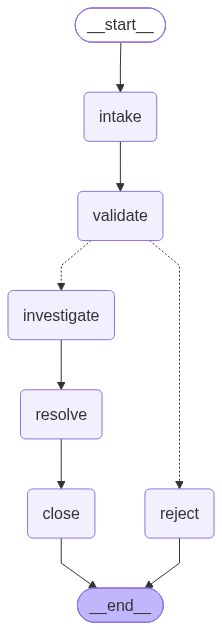

In [93]:
from IPython.display import Image, display

def display_workflow_graph(app):
    """Render the compiled LangGraph workflow as a PNG."""
    graph_png = app.get_graph().draw_mermaid_png()
    display(Image(graph_png))

app = workflow.compile()

display_workflow_graph(app)


In [94]:
# List of workflow outputs
for r in results:
    path = r.get("workflow_path", [])
    print(" → ".join(path))


intake → validation → investigation → resolution → closure
intake → validation → investigation → resolution → closure
intake → validation → investigation → resolution → closure
intake → validation → investigation → resolution → closure
intake → validation → reject


In [95]:
# List of workflow with cleaerer outputs

for index, result in enumerate(results, start=1):
    complaint = result.get("complaint", "Unknown complaint")
    path = result.get("workflow_path", [])
    status = result.get("status", "Unknown")

    print(f"\nRun {index}")
    print(f"Complaint: {complaint}")
    print(f"Path: {' → '.join(path)}")
    print(f"Status: {status}")




Run 1
Complaint: The Downside Up portal opens at different times each day. How do I predict when?
Path: intake → validation → investigation → resolution → closure
Status: closed

Run 2
Complaint: Demogorgons sometimes work together and sometimes fight. What's their deal?
Path: intake → validation → investigation → resolution → closure
Status: closed

Run 3
Complaint: El can move things with her mind but can't lift heavy rocks. Why?
Path: intake → validation → investigation → resolution → closure
Status: closed

Run 4
Complaint: Why do creatures and power lines react so strangely together?
Path: intake → validation → investigation → resolution → closure
Status: closed

Run 5
Complaint: This is not a valid complaint about something random
Path: intake → validation → reject
Status: rejected


In [96]:
for index, r in enumerate(results, start=1):
    print(f"\n--- Result {index} ---")
    print("Category:", repr(r.get("category")))
    print("Valid:", repr(r.get("is_valid")))
    print("Status:", repr(r.get("status")))
    print("Path:", repr(r.get("workflow_path")))


--- Result 1 ---
Category: 'portal'
Valid: True
Status: 'closed'
Path: ['intake', 'validation', 'investigation', 'resolution', 'closure']

--- Result 2 ---
Category: 'monster'
Valid: True
Status: 'closed'
Path: ['intake', 'validation', 'investigation', 'resolution', 'closure']

--- Result 3 ---
Category: 'psychic'
Valid: True
Status: 'closed'
Path: ['intake', 'validation', 'investigation', 'resolution', 'closure']

--- Result 4 ---
Category: 'environmental'
Valid: True
Status: 'closed'
Path: ['intake', 'validation', 'investigation', 'resolution', 'closure']

--- Result 5 ---
Category: 'other'
Valid: False
Status: 'rejected'
Path: ['intake', 'validation', 'reject']


### Step 6: Compare with LangChain

In [97]:
from langchain_core.messages import HumanMessage

# Test a valid complaint using the direct LangChain approach
answer = llm.invoke(
    [HumanMessage(content=test_complaints[0])]
)

print("Direct LLM response:")
print(answer.content)


# Test the invalid complaint
invalid_answer = llm.invoke(
    [HumanMessage(content=test_complaints[-1])]
)

print(f"\n" + "-" * 40)
print("\nDirect LLM response to invalid complaint:")
print(invalid_answer.content)

Direct LLM response:
To predict when the Downside Up portal opens, you can follow these steps:

1. **Collect Data**: Record the opening times of the portal over several days. Note the date and the exact time it opens each day.

2. **Look for Patterns**: Analyze the data for any patterns or trends. Check if the opening times follow a specific sequence, such as opening earlier or later on certain days of the week.

3. **Consider External Factors**: Determine if there are any external factors that might influence the opening times, such as events, lunar phases, or other cyclical occurrences.

4. **Create a Model**: If you notice a consistent pattern, you can create a predictive model based on your observations. This could be as simple as averaging the opening times or using more complex statistical methods if the data supports it.

5. **Test Your Predictions**: Once you have a model, test it against future opening times to see how accurate your predictions are. Adjust your model as necess

| | LangGraph | One LLM call |
|---|---|---|
| Same answer every run? | Mostly: the lore-based investigation and resolution are deterministic, but the intake category comes from an LLM. | Not guaranteed, the answer is generated by the LLM. |
| Invalid complaint rejected? | Yes. | No, the example responds to the invalid complaint instead of rejecting it. |
| Path visible? | Yes, `workflow_path` records the nodes visited. | No, it is a single direct response. |
| Source of each claim? | The investigation uses the matching `LORE` entry and stores it in `evidence`; the resolution repeats that lore. | No source is provided in the shown response. |
| Best for which client case? | Cases needing multiple steps, category validation, and answers grounded in known lore. | Simple, one-off questions where a quick free-form answer is enough. |